## 1. Data exploration and Pre-processing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

seaborn.set_theme(style="whitegrid")

In [3]:
data_url = "https://raw.githubusercontent.com/jinningf-cyber/DSCI552/main/DSCI552-Midterm/student/student-mat.csv"

df = pd.read_csv(data_url, sep=";")
df.head()

df.info()

missing_values_df = df.isnull().sum().to_frame("Missing Values")
missing_values_df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

,Missing Values
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


The dataset contains 395 observations and 33 variables. There are no missing values in the original dataset.

ii

In [5]:
selected_columns = [
    "age", "studytime", "schoolsup", "goout", "Dalc",
    "Walc", "health", "absences", "G3"
]

data = df[selected_columns].copy()

# Encode school support and combine weekday/weekend alcohol consumption.
data["schoolsup"] = data["schoolsup"].map({"no": 0, "yes": 1})
data["alc"] = (data["Dalc"] + data["Walc"]) / 2
data = data.drop(columns=["Dalc", "Walc"])

# Keep the target variable as the last column.
data = data[[
    "age", "studytime", "schoolsup", "goout",
    "health", "absences", "alc", "G3"
]]

data.head()

,age,studytime,schoolsup,goout,health,absences,alc,G3
0,18,2,1,4,3,6,1.0,6
1,17,2,0,3,3,4,1.0,6
2,15,2,1,2,3,10,2.5,10
3,15,3,0,2,5,2,1.0,15
4,16,2,0,2,5,4,1.5,10


iii

In [6]:
independent_variables = [col for col in data.columns if col != "G3"]
outlier_rows = []

for col in independent_variables:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    LB = Q1 - 1.5 * IQR
    UB = Q3 + 1.5 * IQR

    number_of_outliers = ((data[col] < LB) | (data[col] > UB)).sum()

    outlier_rows.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": LB,
        "Upper Bound": UB,
        "Number of Outliers": number_of_outliers
    })

outlier_counts_df = pd.DataFrame(outlier_rows)
outlier_counts_df

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Number of Outliers
0,age,16.0,18.0,2.0,13.00,21.00,1
1,studytime,1.0,2.0,1.0,-0.50,3.50,27
2,schoolsup,0.0,0.0,0.0,0.00,0.00,51
3,goout,2.0,4.0,2.0,-1.00,7.00,0
4,health,3.0,5.0,2.0,0.00,8.00,0
5,absences,0.0,8.0,8.0,-12.00,20.00,15
6,alc,1.0,2.5,1.5,-1.25,4.75,9


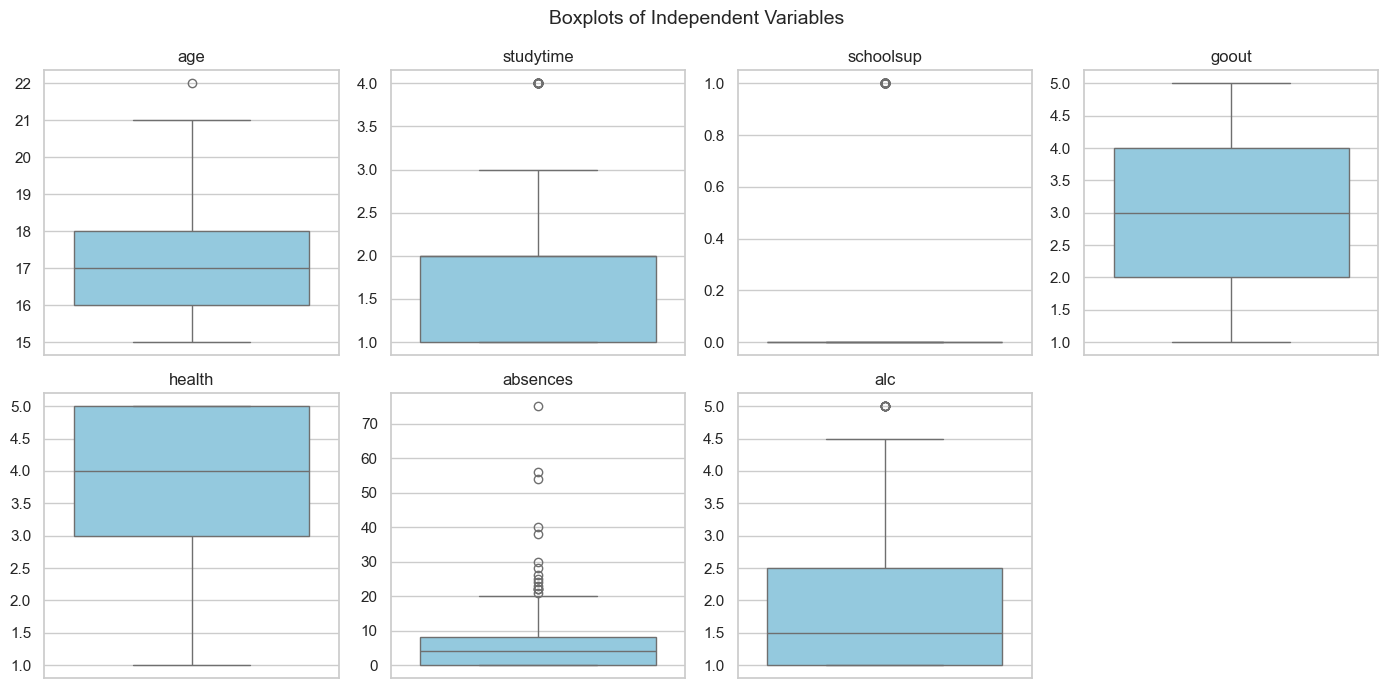

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, col in enumerate(independent_variables):
    seaborn.boxplot(y=data[col], ax=axes[i], color="skyblue")
    axes[i].set_title(col)
    axes[i].set_ylabel("")

axes[-1].axis("off")
plt.suptitle("Boxplots of Independent Variables", fontsize=14)
plt.tight_layout()
plt.show()

The IQR rule identifies outliers in `age` (1), `studytime` (27), `schoolsup` (51), `absences` (15), and `alc` (9). It finds no outliers in `goout` or `health`.

For the binary variable `schoolsup`, both quartiles equal 0, so the IQR equals 0 and every value of 1 is flagged. These 51 observations represent the less common category rather than invalid data, so they should not be removed automatically.

iv

In [8]:
X = data.drop(columns=["G3"])
y = data["G3"]

scaler = StandardScaler()
X_standardized = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

X_standardized.head()

,age,studytime,schoolsup,goout,health,absences,alc
0,1.023046,-0.042286,2.597133,0.801479,-0.399289,0.036424,-0.894179
1,0.238380,-0.042286,-0.385040,-0.097908,-0.399289,-0.213796,-0.894179
2,-1.330954,-0.042286,2.597133,-0.997295,-0.399289,0.536865,0.619538
3,-1.330954,1.150779,-0.385040,-0.997295,1.041070,-0.464016,-0.894179
4,-0.546287,-0.042286,-0.385040,-0.997295,1.041070,-0.213796,-0.389607


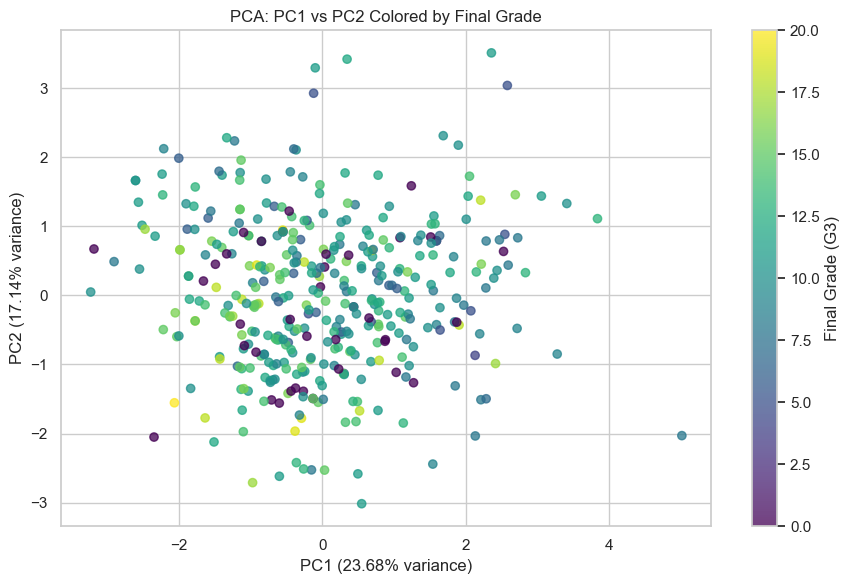

In [9]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_standardized)

pca_df = pd.DataFrame(
    principal_components,
    columns=["PC1", "PC2"]
)

pca_df["G3"] = y.to_numpy()

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["G3"],
    cmap="viridis",
    alpha=0.75
)

plt.colorbar(scatter, label="Final Grade (G3)")
plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.2f}% variance)"
)
plt.title("PCA: PC1 vs PC2 Colored by Final Grade")
plt.tight_layout()
plt.show()

In [10]:
pca_loadings_df = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2"]
)

pca_loadings_df["Absolute PC1"] = pca_loadings_df["PC1"].abs()
pca_loadings_df["Absolute PC2"] = pca_loadings_df["PC2"].abs()

pca_loadings_df.round(3)

,PC1,PC2,Absolute PC1,Absolute PC2
age,0.382,-0.589,0.382,0.589
studytime,-0.330,-0.386,0.330,0.386
schoolsup,-0.248,0.464,0.248,0.464
goout,0.494,0.140,0.494,0.140
health,0.081,0.401,0.081,0.401
absences,0.280,-0.183,0.280,0.183
alc,0.596,0.274,0.596,0.274


In [11]:
print(
    "PC1 explained variance:",
    round(pca.explained_variance_ratio_[0], 4)
)

print(
    "PC2 explained variance:",
    round(pca.explained_variance_ratio_[1], 4)
)

print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

print(
    "Largest absolute PC1 loading:",
    pca_loadings_df["Absolute PC1"].idxmax()
)

print(
    "Largest absolute PC2 loading:",
    pca_loadings_df["Absolute PC2"].idxmax()
)

PC1 explained variance: 0.2368
PC2 explained variance: 0.1714
Total explained variance: 0.4081
Largest absolute PC1 loading: alc
Largest absolute PC2 loading: age


PC1 explains 23.68% of the standardized feature variance and is influenced most strongly by `alc` (absolute loading 0.596) and `goout` (0.494).

PC2 explains 17.14% and is influenced most strongly by `age` (0.589), followed by `schoolsup` (0.464), `health` (0.401), and `studytime` (0.386).

The sign of a PCA loading can be reversed without changing the component, so absolute loadings are used to measure contribution. Together, PC1 and PC2 explain 40.81% of the variance.

Following the assignment instruction, `X_standardized` is retained for the remaining problems. In a production prediction workflow, the scaler should be fitted on the training set only to avoid test-data leakage.

## b. Linear Regression

i

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X_standardized,
    y,
    test_size=0.20,
    random_state=552
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (316, 7)
X_test shape: (79, 7)
y_train shape: (316,)
y_test shape: (79,)


ii

In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=0.1)": Ridge(alpha=0.1),
    "Lasso (alpha=0.1)": Lasso(alpha=0.1, max_iter=10000)
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

print("Models fitted:")

for name in models:
    print(name)

Models fitted:
Linear Regression
Ridge (alpha=0.1)
Lasso (alpha=0.1)


iii

In [15]:
evaluation_rows = []

for name, prediction in predictions.items():
    MAE = mean_absolute_error(y_test, prediction)
    RMSE = np.sqrt(mean_squared_error(y_test, prediction))
    R2 = r2_score(y_test, prediction)

    evaluation_rows.append({
        "Model": name,
        "MAE": MAE,
        "RMSE": RMSE,
        "R2": R2
    })

evaluation_df = pd.DataFrame(evaluation_rows)
evaluation_df = evaluation_df.set_index("Model")

evaluation_df.round(4)

,MAE,RMSE,R2
Model,,,
Linear Regression,3.4180,4.7558,0.0282
Ridge (alpha=0.1),3.4181,4.7559,0.0282
Lasso (alpha=0.1),3.4471,4.7938,0.0126


In [16]:
best_models_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Best Model": [
        evaluation_df["MAE"].idxmin(),
        evaluation_df["RMSE"].idxmin(),
        evaluation_df["R2"].idxmax()
    ],
    "Best Value": [
        evaluation_df["MAE"].min(),
        evaluation_df["RMSE"].min(),
        evaluation_df["R2"].max()
    ]
})

best_models_df.round(4)

,Metric,Best Model,Best Value
0,MAE,Linear Regression,3.4180
1,RMSE,Linear Regression,4.7558
2,R2,Linear Regression,0.0282


Linear Regression is the best model for all three test metrics, although its advantage over Ridge is extremely small. Its MAE is 3.4180 grade points, its RMSE is 4.7558, and its $R^2$ is 0.0282.

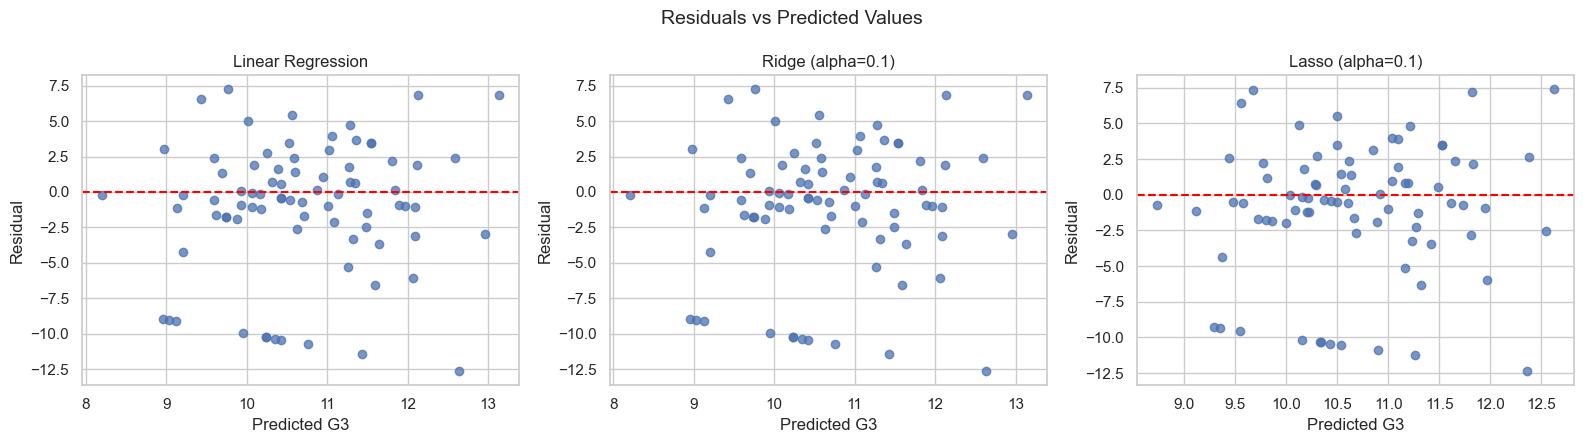

In [17]:
#Residual Analysis
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, prediction) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - prediction

    ax.scatter(prediction, residuals, alpha=0.75)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Predicted G3")
    ax.set_ylabel("Residual")

plt.suptitle("Residuals vs Predicted Values", fontsize=14)
plt.tight_layout()
plt.show()

The three residual plots are almost identical. The residuals remain widely dispersed around zero, and the fitted values occupy a relatively narrow range. This is consistent with the low $R^2$: the selected predictors do not explain most of the variation in final grades.

iv

$R^2$ measures the proportion of test-set variation in `G3` explained by the model relative to predicting the test mean.

The Linear Regression and Ridge models explain only about 2.8% of the variation, while Lasso explains about 1.3%. These values are close to zero, so all three models have weak predictive power with the selected features.

The positive values indicate a small improvement over the mean baseline, but not a practically strong one.

v

In [18]:
coefficient_df = pd.DataFrame({
    "Feature": ["Intercept"] + independent_variables
})

for name, model in models.items():
    coefficient_df[name] = [
        model.intercept_
    ] + list(model.coef_)

coefficient_df.round(4)

,Feature,Linear Regression,Ridge (alpha=0.1),Lasso (alpha=0.1)
0,Intercept,10.6294,10.6294,10.6251
1,age,-0.7811,-0.7807,-0.6304
2,studytime,0.4448,0.4447,0.3491
3,schoolsup,-0.6825,-0.6822,-0.5475
4,goout,-0.5825,-0.5823,-0.4856
5,health,-0.2433,-0.2432,-0.1416
6,absences,0.1928,0.1927,0.0720
7,alc,0.0371,0.0369,-0.0000


vi

Because all predictors are standardized, each coefficient is the expected change in `G3` for a one-standard-deviation increase in that predictor, holding the other predictors constant.

- `age` has the largest negative relationship across all models (Linear coefficient = -0.7811).
- `studytime` has a positive relationship (0.4448), so more study time is associated with a higher predicted grade.
- `schoolsup` has a negative relationship (-0.6825). This should not be interpreted causally; students who need extra support may already face academic difficulties.
- `goout` has a negative relationship (-0.5825).
- `health` has a small negative relationship (-0.2433) in this multivariable fit.
- `absences` has a small positive coefficient (0.1928), which is counterintuitive and likely reflects sampling variation, correlations among predictors, and the weak overall model.
- `alc` is nearly unrelated to the outcome after controlling for the other selected variables (0.0371), and Lasso shrinks it exactly to zero.

The coefficient signs describe conditional associations in this fitted sample and do not establish causal effects.

vii

Ridge uses an L2 penalty and continuously shrinks all coefficients toward zero, but normally keeps every feature in the model. Lasso uses an L1 penalty and can set coefficients exactly to zero, so it also performs feature selection.

With $\alpha=0.1$, Ridge is almost identical to ordinary Linear Regression because the penalty is weak relative to this standardized dataset.

Lasso shrinks all coefficients more strongly and removes `alc`, but its test MAE and RMSE are slightly higher and its $R^2$ is lower. Therefore, regularization does not improve test performance here.

The primary limitation appears to be weak information in the selected predictors rather than excessive coefficient variance or severe overfitting.

viii

In [19]:
alpha_values = [0.01, 0.1, 1, 10]
alpha_rows = []

for alpha in alpha_values:
    regularized_models = {
        "Ridge": Ridge(alpha=alpha),
        "Lasso": Lasso(alpha=alpha, max_iter=10000)
    }

    for name, model in regularized_models.items():
        model.fit(X_train, y_train)
        prediction = model.predict(X_test)

        MAE = mean_absolute_error(y_test, prediction)
        RMSE = np.sqrt(mean_squared_error(y_test, prediction))
        R2 = r2_score(y_test, prediction)
        number_of_nonzero = np.count_nonzero(model.coef_)

        alpha_rows.append({
            "Model": name,
            "Alpha": alpha,
            "MAE": MAE,
            "RMSE": RMSE,
            "R2": R2,
            "Non-zero Coefficients": number_of_nonzero
        })

alpha_results_df = pd.DataFrame(alpha_rows)
alpha_results_df.round(4)

,Model,Alpha,MAE,RMSE,R2,Non-zero Coefficients
0,Ridge,0.01,3.4180,4.7558,0.0282,7
1,Lasso,0.01,3.4202,4.7605,0.0262,7
2,Ridge,0.10,3.4181,4.7559,0.0282,7
3,Lasso,0.10,3.4471,4.7938,0.0126,6
4,Ridge,1.00,3.4185,4.7563,0.0280,7
5,Lasso,1.00,3.5987,4.9255,-0.0424,0
6,Ridge,10.00,3.4231,4.7604,0.0263,7
7,Lasso,10.00,3.5987,4.9255,-0.0424,0


As $\alpha$ increases, coefficients shrink more strongly. Training error generally increases, but test performance does not have to change monotonically because regularization trades variance for bias.

In these results, stronger regularization does not improve the test metrics: MAE and RMSE increase and $R^2$ decreases.

Lasso sets all seven coefficients to zero by $\alpha=1$, reducing the model to an intercept-only prediction. Ridge shrinks more gradually and retains all coefficients.

ix

Several changes may improve prediction:

1. Add `G1` and `G2`, which are earlier-period grades and are expected to be strong predictors of `G3`. If the goal is early intervention before these grades are available, keep them excluded and state that restriction clearly.

2. Add other available variables such as past failures, parental education, school, paid classes, family support, and desire for higher education.

3. Tune $\alpha$ using cross-validation within the training set instead of relying on one fixed value.

The low test $R^2$ suggests that adding more informative predictors, especially prior achievement, is likely to help more than simply increasing regularization.

## Final conclusion

Using the seven required standardized predictors, all three linear models have weak test performance.

Ordinary Linear Regression is marginally best, with MAE = 3.4180, RMSE = 4.7558, and $R^2$ = 0.0282.

Ridge produces nearly identical coefficients and metrics, while Lasso removes `alc` but slightly worsens performance.

The results indicate that the selected variables alone do not contain enough linear signal to predict final grades accurately.